In [1]:
import json, random, shutil
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
IMG_SIZE = 300
NUM_CLASSES = 5
USE_CIRCULAR_MASK = True
USE_CLAHE = True
USE_BEN_GRAHAM = True
OVERSAMPLE_TARGET_PER_CLASS = None  # None = majority class size

random.seed(SEED)
np.random.seed(SEED)

CLASS_NAMES = {
    0: "No DR", 1: "Mild", 2: "Moderate",
    3: "Severe", 4: "Proliferative DR"
}
print("OpenCV:", cv2.__version__)

OpenCV: 4.13.0


In [2]:
# Auto-detect the official/repacked APTOS dataset under /kaggle/input.
def find_aptos_dataset(root=Path("/kaggle/input")):
    candidates = []
    for csv_path in root.rglob("train.csv"):
        try:
            sample = pd.read_csv(csv_path, nrows=5)
        except Exception:
            continue
        if not {"id_code", "diagnosis"}.issubset(sample.columns):
            continue
        for img_dir in (csv_path.parent/"train_images",
                        csv_path.parent/"train_images"/"train_images"):
            if img_dir.exists():
                candidates.append((csv_path, img_dir))
    if not candidates:
        raise FileNotFoundError(
            "APTOS train.csv + train_images not found. Attach the "
            "'APTOS 2019 Blindness Detection' competition data."
        )
    candidates.sort(key=lambda x: len(list(x[1].glob("*.png"))), reverse=True)
    return candidates[0]

TRAIN_CSV, ORIGINAL_IMAGE_DIR = find_aptos_dataset()
df = pd.read_csv(TRAIN_CSV)
df["diagnosis"] = df["diagnosis"].astype(int)

def resolve_image_path(image_id):
    for ext in (".png", ".jpg", ".jpeg"):
        p = ORIGINAL_IMAGE_DIR / f"{image_id}{ext}"
        if p.exists():
            return p
    return None

df["source_path"] = df["id_code"].map(resolve_image_path)
assert df["source_path"].notna().all(), "Some labeled images are missing."
assert set(df["diagnosis"]).issubset(set(range(5)))

print("CSV:", TRAIN_CSV)
print("Images:", ORIGINAL_IMAGE_DIR)
display(df.head())
display(df["diagnosis"].value_counts().sort_index().rename("count").to_frame())

CSV: /kaggle/input/competitions/aptos2019-blindness-detection/train.csv
Images: /kaggle/input/competitions/aptos2019-blindness-detection/train_images


,id_code,diagnosis,source_path
0,000c1434d8d7,2,/kaggle/input/competitions/aptos2019-blindness...
1,001639a390f0,4,/kaggle/input/competitions/aptos2019-blindness...
2,0024cdab0c1e,1,/kaggle/input/competitions/aptos2019-blindness...
3,002c21358ce6,0,/kaggle/input/competitions/aptos2019-blindness...
4,005b95c28852,0,/kaggle/input/competitions/aptos2019-blindness...


,count
diagnosis,
0,1805
1,370
2,999
3,193
4,295


In [3]:
train_df, temp_df = train_test_split(
    df, test_size=0.20, stratify=df["diagnosis"],
    random_state=SEED, shuffle=True
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["diagnosis"],
    random_state=SEED, shuffle=True
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

assert set(train_df.id_code).isdisjoint(val_df.id_code)
assert set(train_df.id_code).isdisjoint(test_df.id_code)
assert set(val_df.id_code).isdisjoint(test_df.id_code)

summary = pd.DataFrame({
    "train": train_df.diagnosis.value_counts().sort_index(),
    "val": val_df.diagnosis.value_counts().sort_index(),
    "test": test_df.diagnosis.value_counts().sort_index(),
}).fillna(0).astype(int)
display(summary)
print(len(train_df), len(val_df), len(test_df), "total =", len(df))

,train,val,test
diagnosis,,,
0,1444,180,181
1,296,37,37
2,799,100,100
3,154,20,19
4,236,29,30


2929 366 367 total = 3662


In [4]:
def crop_dark_border_rgb(img, tol=7):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    mask = gray > tol
    if not mask.any():
        return img
    ys, xs = np.where(mask)
    return img[ys.min():ys.max()+1, xs.min():xs.max()+1]

def center_square(img):
    h, w = img.shape[:2]
    side = min(h, w)
    y0, x0 = (h-side)//2, (w-side)//2
    return img[y0:y0+side, x0:x0+side]

def circular_mask(img):
    h, w = img.shape[:2]
    mask = np.zeros((h, w), np.uint8)
    cv2.circle(mask, (w//2, h//2), int(0.50*min(h,w)), 255, -1)
    return cv2.bitwise_and(img, img, mask=mask)

def apply_clahe_rgb(img, clip_limit=2.0, tile_grid=(8,8)):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=clip_limit,
                        tileGridSize=tile_grid).apply(l)
    return cv2.cvtColor(cv2.merge((l,a,b)), cv2.COLOR_LAB2RGB)

def ben_graham_enhance(img, sigma=10.0):
    # Mild local-background subtraction at the final 300x300 resolution.
    blur = cv2.GaussianBlur(img, (0,0), sigmaX=sigma, sigmaY=sigma)
    return cv2.addWeighted(img, 4.0, blur, -4.0, 128.0)

def preprocess_image(path):
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise ValueError(f"Cannot read {path}")
    img = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    img = crop_dark_border_rgb(img)
    img = center_square(img)
    interp = cv2.INTER_AREA if max(img.shape[:2]) > IMG_SIZE else cv2.INTER_CUBIC
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=interp)
    if USE_CIRCULAR_MASK:
        img = circular_mask(img)
    if USE_CLAHE:
        img = apply_clahe_rgb(img)
    if USE_BEN_GRAHAM:
        img = ben_graham_enhance(img)
    return np.clip(img, 0, 255).astype(np.uint8)

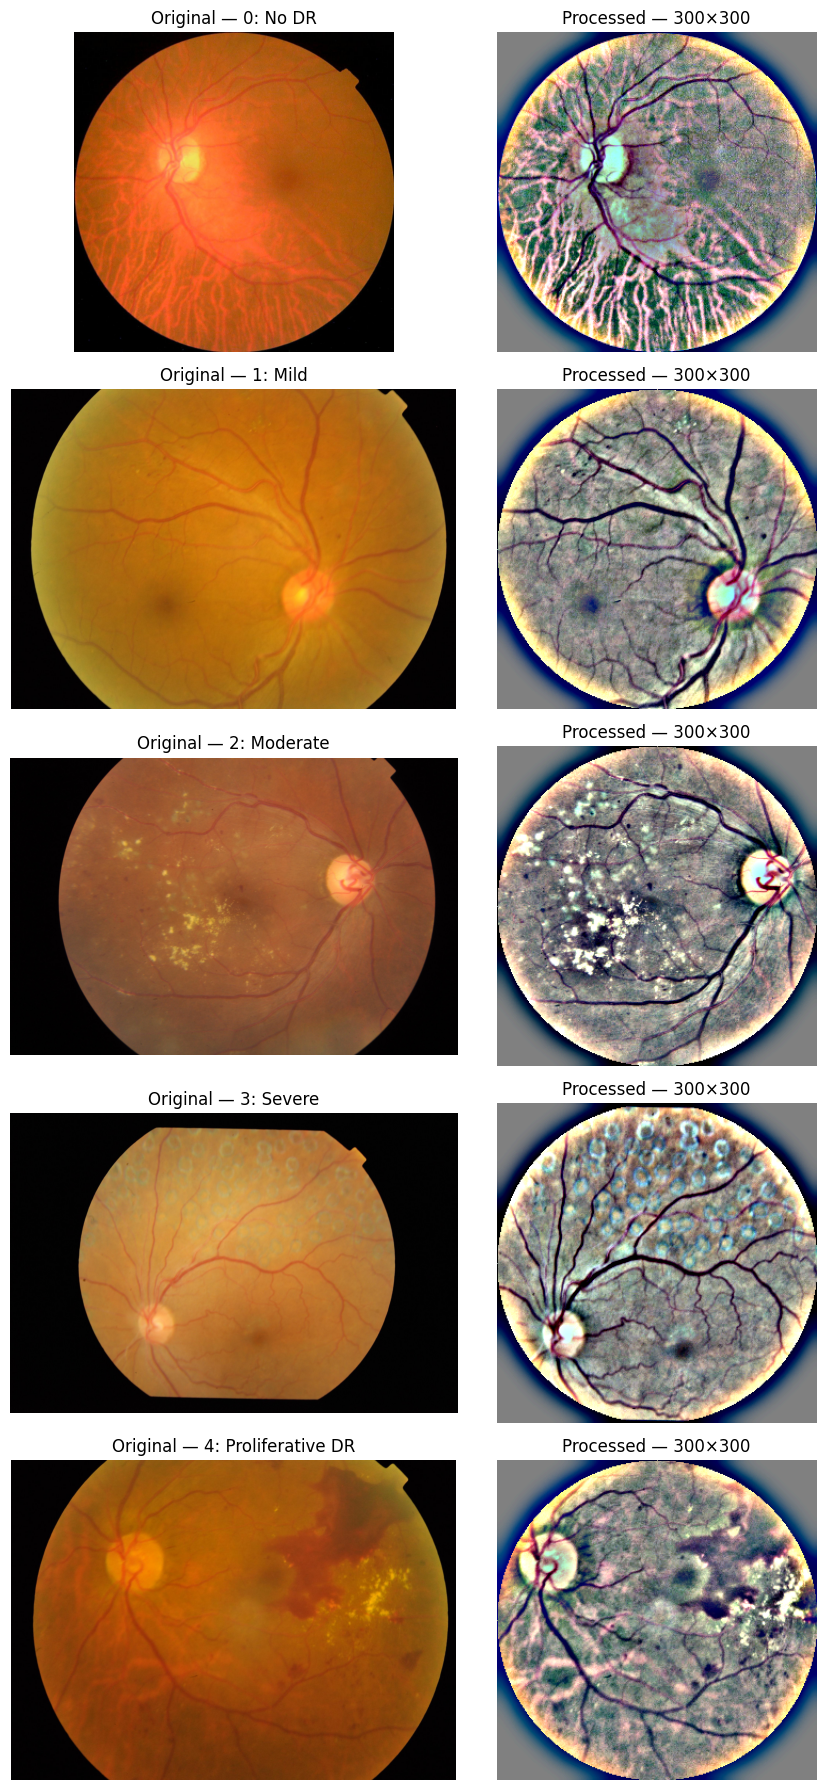

In [5]:
# Visual sanity check: one image from each class.
samples = (df.groupby("diagnosis", group_keys=False)
             .sample(1, random_state=SEED)
             .sort_values("diagnosis"))

fig, axes = plt.subplots(5, 2, figsize=(9, 18))
for i, (_, row) in enumerate(samples.iterrows()):
    raw = cv2.cvtColor(cv2.imread(str(row.source_path)), cv2.COLOR_BGR2RGB)
    proc = preprocess_image(row.source_path)
    axes[i,0].imshow(raw)
    axes[i,0].set_title(f"Original — {row.diagnosis}: {CLASS_NAMES[row.diagnosis]}")
    axes[i,1].imshow(proc)
    axes[i,1].set_title("Processed — 300×300")
    axes[i,0].axis("off"); axes[i,1].axis("off")
plt.tight_layout()
plt.show()

In [6]:
# Output structure.
OUTPUT_ROOT = Path("/kaggle/working/aptos_processed_300")
TRAIN_ORIGINAL_DIR = OUTPUT_ROOT/"train_original"
TRAIN_BALANCED_DIR = OUTPUT_ROOT/"train"
VAL_DIR = OUTPUT_ROOT/"val"
TEST_DIR = OUTPUT_ROOT/"test"
META_DIR = OUTPUT_ROOT/"metadata"

if OUTPUT_ROOT.exists():
    shutil.rmtree(OUTPUT_ROOT)
for p in [TRAIN_ORIGINAL_DIR, TRAIN_BALANCED_DIR, VAL_DIR, TEST_DIR, META_DIR]:
    p.mkdir(parents=True, exist_ok=True)

def save_rgb_png(img, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    ok = cv2.imwrite(
        str(path), cv2.cvtColor(img, cv2.COLOR_RGB2BGR),
        [cv2.IMWRITE_PNG_COMPRESSION, 3]
    )
    if not ok:
        raise IOError(f"Failed to save {path}")

def preprocess_split(frame, out_dir, split_name):
    records = []
    for _, row in tqdm(frame.iterrows(), total=len(frame), desc=split_name):
        cls = int(row.diagnosis)
        dst = out_dir/str(cls)/f"{row.id_code}.png"
        save_rgb_png(preprocess_image(row.source_path), dst)
        records.append({
            "id_code": row.id_code, "diagnosis": cls,
            "split": split_name, "is_augmented": False,
            "source_id": row.id_code, "filepath": str(dst)
        })
    return pd.DataFrame(records)

train_original_meta = preprocess_split(train_df, TRAIN_ORIGINAL_DIR, "train_original")
val_meta = preprocess_split(val_df, VAL_DIR, "val")
test_meta = preprocess_split(test_df, TEST_DIR, "test")

train_original:   0%|          | 0/2929 [00:00<?, ?it/s]

val:   0%|          | 0/366 [00:00<?, ?it/s]

test:   0%|          | 0/367 [00:00<?, ?it/s]

In [7]:
rng = np.random.default_rng(SEED)

def augment_retina(img, rng):
    h, w = img.shape[:2]
    if rng.random() < 0.5:
        img = cv2.flip(img, 1)
    if rng.random() < 0.25:
        img = cv2.flip(img, 0)

    angle = float(rng.uniform(-20, 20))
    scale = float(rng.uniform(0.95, 1.05))
    tx, ty = float(rng.uniform(-.03,.03)*w), float(rng.uniform(-.03,.03)*h)
    M = cv2.getRotationMatrix2D((w/2,h/2), angle, scale)
    M[0,2] += tx; M[1,2] += ty
    img = cv2.warpAffine(
        img, M, (w,h), flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT, borderValue=(0,0,0)
    )

    alpha = float(rng.uniform(.90, 1.10))
    beta = float(rng.uniform(-10, 10))
    img = cv2.convertScaleAbs(img, alpha=alpha, beta=beta)
    if USE_CIRCULAR_MASK:
        img = circular_mask(img)
    return img

balanced_records = []

# Copy originals into the final balanced train directory.
for _, row in tqdm(train_original_meta.iterrows(),
                   total=len(train_original_meta), desc="Copy originals"):
    cls = int(row.diagnosis)
    src = Path(row.filepath)
    dst = TRAIN_BALANCED_DIR/str(cls)/src.name
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(src, dst)
    balanced_records.append({
        "id_code": row.id_code, "diagnosis": cls, "split": "train",
        "is_augmented": False, "source_id": row.source_id,
        "filepath": str(dst)
    })

counts = train_original_meta.diagnosis.value_counts().sort_index()
target = int(counts.max()) if OVERSAMPLE_TARGET_PER_CLASS is None else int(OVERSAMPLE_TARGET_PER_CLASS)
assert target >= counts.max()

for cls in range(NUM_CLASSES):
    class_rows = train_original_meta[train_original_meta.diagnosis == cls].reset_index(drop=True)
    needed = target - len(class_rows)
    if needed <= 0:
        continue

    sampled = rng.integers(0, len(class_rows), size=needed)
    for aug_i, idx in enumerate(tqdm(sampled, desc=f"class {cls} +{needed}")):
        src_row = class_rows.iloc[int(idx)]
        bgr = cv2.imread(src_row.filepath)
        img = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        img = augment_retina(img, rng)

        name = f"{src_row.source_id}__aug_{cls}_{aug_i:05d}.png"
        dst = TRAIN_BALANCED_DIR/str(cls)/name
        save_rgb_png(img, dst)
        balanced_records.append({
            "id_code": Path(name).stem, "diagnosis": cls, "split": "train",
            "is_augmented": True, "source_id": src_row.source_id,
            "filepath": str(dst)
        })

train_balanced_meta = pd.DataFrame(balanced_records)
display(train_balanced_meta.diagnosis.value_counts().sort_index().rename("balanced_count"))
assert train_balanced_meta.diagnosis.value_counts().nunique() == 1

Copy originals:   0%|          | 0/2929 [00:00<?, ?it/s]

class 1 +1148:   0%|          | 0/1148 [00:00<?, ?it/s]

class 2 +645:   0%|          | 0/645 [00:00<?, ?it/s]

class 3 +1290:   0%|          | 0/1290 [00:00<?, ?it/s]

class 4 +1208:   0%|          | 0/1208 [00:00<?, ?it/s]

diagnosis
0    1444
1    1444
2    1444
3    1444
4    1444
Name: balanced_count, dtype: int64

In [8]:
classes = np.arange(NUM_CLASSES)

w_original = compute_class_weight(
    class_weight="balanced", classes=classes,
    y=train_original_meta.diagnosis.to_numpy()
)
class_weights_original = {int(c): float(w) for c,w in zip(classes, w_original)}

w_oversampled = compute_class_weight(
    class_weight="balanced", classes=classes,
    y=train_balanced_meta.diagnosis.to_numpy()
)
class_weights_oversampled = {int(c): float(w) for c,w in zip(classes, w_oversampled)}

print("Original-train weights:")
print(json.dumps(class_weights_original, indent=2))
print("\nOversampled-train weights:")
print(json.dumps(class_weights_oversampled, indent=2))

Original-train weights:
{
  "0": 0.4056786703601108,
  "1": 1.979054054054054,
  "2": 0.7331664580725907,
  "3": 3.803896103896104,
  "4": 2.4822033898305085
}

Oversampled-train weights:
{
  "0": 1.0,
  "1": 1.0,
  "2": 1.0,
  "3": 1.0,
  "4": 1.0
}


In [9]:
# Save metadata and configuration.
train_original_meta.to_csv(META_DIR/"train_original.csv", index=False)
train_balanced_meta.to_csv(META_DIR/"train_balanced.csv", index=False)
val_meta.to_csv(META_DIR/"val.csv", index=False)
test_meta.to_csv(META_DIR/"test.csv", index=False)

with open(META_DIR/"class_weights_original_train.json", "w") as f:
    json.dump(class_weights_original, f, indent=2)
with open(META_DIR/"class_weights_oversampled_train.json", "w") as f:
    json.dump(class_weights_oversampled, f, indent=2)

config = {
    "seed": SEED,
    "image_size": [300,300],
    "split": {"train": .8, "val": .1, "test": .1},
    "stratified": True,
    "preprocessing": {
        "dark_border_crop": True,
        "center_square": True,
        "circular_mask": USE_CIRCULAR_MASK,
        "clahe_luminance": USE_CLAHE,
        "ben_graham_style": USE_BEN_GRAHAM
    },
    "oversampling": {
        "train_only": True,
        "target_per_class": target,
        "physical_augmented_pngs": True
    },
    "recommended_policy": {
        "train_balanced": "No additional class weights by default",
        "train_original": "Use class_weights_original_train.json if desired"
    }
}
with open(META_DIR/"preprocessing_config.json", "w") as f:
    json.dump(config, f, indent=2)

final_table = pd.DataFrame({
    "train_original": train_original_meta.diagnosis.value_counts().sort_index(),
    "train_balanced": train_balanced_meta.diagnosis.value_counts().sort_index(),
    "validation": val_meta.diagnosis.value_counts().sort_index(),
    "test": test_meta.diagnosis.value_counts().sort_index(),
}).fillna(0).astype(int)
display(final_table)

,train_original,train_balanced,validation,test
diagnosis,,,,
0,1444,1444,180,181
1,296,1444,37,37
2,799,1444,100,100
3,154,1444,20,19
4,236,1444,29,30


# Part 2 — ResNet-50: from scratch vs pretrained + fine-tune
Both models use the same data (`train_balanced` / `val` / `test`). The best epoch is picked by validation QWK (the APTOS metric).

In [ ]:
import copy
import torch, torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 32
torch.manual_seed(SEED)

In [ ]:
norm = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])  # ImageNet stats
train_tf = T.Compose([T.RandomHorizontalFlip(), T.RandomRotation(15), T.ToTensor(), norm])
eval_tf = T.Compose([T.ToTensor(), norm])

class RetinaDataset(Dataset):
    def __init__(self, meta, tf):
        self.paths = meta["filepath"].tolist()
        self.labels = meta["diagnosis"].tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

def loader(meta, tf, shuffle):
    return DataLoader(RetinaDataset(meta, tf), BATCH_SIZE, shuffle=shuffle, num_workers=2)

train_loader = loader(train_balanced_meta, train_tf, True)
val_loader = loader(val_meta, eval_tf, False)
test_loader = loader(test_meta, eval_tf, False)

In [ ]:
def build_resnet50(pretrained, freeze_layers=()):
    weights = models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
    model = models.resnet50(weights=weights)
    for name, p in model.named_parameters():
        p.requires_grad = not name.startswith(tuple(freeze_layers))  # frozen layers keep ImageNet weights
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)  # new 5-class head
    return model.to(DEVICE)

def evaluate(model, data_loader):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for x, y in data_loader:
            preds += model(x.to(DEVICE)).argmax(1).cpu().tolist()
            labels += y.tolist()
    return preds, labels

criterion = nn.CrossEntropyLoss()

def train(model, optimizer, epochs, name):
    best_qwk, best_state = -1, None
    for epoch in range(1, epochs + 1):
        model.train()
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            criterion(model(x), y).backward()
            optimizer.step()

        preds, labels = evaluate(model, val_loader)
        acc = accuracy_score(labels, preds)
        qwk = cohen_kappa_score(labels, preds, weights="quadratic")
        print(f"[{name}] epoch {epoch}/{epochs}  val acc {acc:.3f}  val QWK {qwk:.3f}")

        if qwk > best_qwk:  # keep the best epoch
            best_qwk, best_state = qwk, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)

## Model 1 — ResNet-50 without pretraining

In [ ]:
model_scratch = build_resnet50(pretrained=False)
train(model_scratch, torch.optim.Adam(model_scratch.parameters(), lr=1e-3),
      epochs=30, name="scratch")

## Model 2 — ResNet-50 pretrained on ImageNet (partial fine-tune)
Load the pretrained weights, freeze the early layers, and train the remaining layers in a single stage. Freezing fewer layers (edit `FREEZE_LAYERS`) adapts more but overfits more easily.

In [ ]:
# Freeze the early layers (generic edges/textures); train layer3, layer4 and the new head.
FREEZE_LAYERS = ["conv1", "bn1", "layer1", "layer2"]

model_ft = build_resnet50(pretrained=True, freeze_layers=FREEZE_LAYERS)
params = [p for p in model_ft.parameters() if p.requires_grad]
train(model_ft, torch.optim.Adam(params, lr=1e-4), epochs=20, name="pretrained")

## Test results

In [ ]:
rows = {}
for name, model in [("scratch", model_scratch), ("pretrained + fine-tune", model_ft)]:
    preds, labels = evaluate(model, test_loader)
    rows[name] = {"accuracy": accuracy_score(labels, preds),
                  "QWK": cohen_kappa_score(labels, preds, weights="quadratic")}
    print(name, "confusion matrix (rows = true, cols = predicted):")
    print(confusion_matrix(labels, preds), "\n")

pd.DataFrame(rows).T.round(3)